# Adaptive SET

Compare dense, fixed SET, and adaptive SET. Short runs check execution only.


## Setup

Use matching models, splits, and seeds. Each target adapts its own budget using validation loss. Training uses dense tensors.


In [1]:
"""Validation-controlled appliance-specific SET; dense execution, not sparse kernels."""
from dataclasses import dataclass, asdict
from pathlib import Path
import argparse
import csv
import hashlib
import json
import time
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

@dataclass
class Config:
    mode: str = 'smoke'
    epochs: int = 4
    seeds: tuple = (42,)
    architectures: tuple = ('DNN', 'CNN')
    batch_size: int = 64
    learning_rate: float = .001
    epsilon: float = 20.
    rewire_fraction: float = .3
    min_density: float = .02
    max_density: float = .6
    shrink_factor: float = .8
    grow_factor: float = 1.25
    tolerance: float = .02
    warmup_epochs: int = 1
    selection_penalty: float = .02
    @classmethod
    def full(cls):
        return cls(mode='full', epochs=50, seeds=(42,43,44), warmup_epochs=5)

@keras.utils.register_keras_serializable(package='AdaptiveSET')
class MaskedDense(layers.Layer):
    def __init__(self, units=100, **kwargs):
        super().__init__(**kwargs)
        self.units = units
    def build(self, shape):
        self.kernel = self.add_weight(name='kernel', shape=(int(shape[-1]), self.units), initializer='glorot_uniform')
        self.bias = self.add_weight(name='bias', shape=(self.units,), initializer='zeros')
        self.mask = self.add_weight(name='mask', shape=self.kernel.shape, initializer='ones', trainable=False)
    def call(self, inputs):
        return tf.nn.relu(tf.matmul(inputs, self.kernel * self.mask) + self.bias)
    def get_config(self):
        return dict(super().get_config(), units=self.units)

class BudgetController:
    """Each target has its own controller; only validation BCE is observed."""
    def __init__(self, cfg):
        self.cfg, self.best = cfg, float('inf')
    def decide(self, epoch, val_bce, current, total):
        cfg = self.cfg
        acceptable = val_bce <= self.best * (1 + cfg.tolerance)
        self.best = min(self.best, val_bce)
        if epoch + 1 < cfg.warmup_epochs:
            return current, 'warmup'
        factor = cfg.shrink_factor if acceptable else cfg.grow_factor
        lower, upper = int(np.ceil(cfg.min_density*total)), int(np.floor(cfg.max_density*total))
        budget = int(np.clip(round(current * factor), lower, upper))
        return budget, 'shrink' if acceptable else 'grow'

def load_data(data_dir, cfg):
    data_dir = Path(data_dir)
    x = np.loadtxt(data_dir/'samX.csv', delimiter=',', skiprows=1, usecols=range(1,601), dtype=np.float32)
    y = np.loadtxt(data_dir/'samY.csv', delimiter=',', skiprows=1, usecols=range(1,5), dtype=np.float32)
    assert x.shape == (10000,600) and y.shape == (10000,4)
    assert np.isfinite(x).all() and np.isin(y,[0,1]).all()
    # Fixed partition boundaries, identical for every method/target/seed.
    train, val, test = np.arange(3600,10000), np.arange(2000,3600), np.arange(2000)
    if cfg.mode == 'smoke':
        train, val, test = train[:128], val[:64], test[:64]
    # Exact duplicate mixtures must not occur across evaluation partitions.
    # Priority: test, then validation, then training. Within-partition repeats remain.
    fingerprints = [hashlib.sha256(row.tobytes()).digest() for row in x]
    seen = set()
    clean, removed = {}, {}
    for name, indices in [('test',test),('validation',val),('train',train)]:
        kept = np.array([i for i in indices if fingerprints[i] not in seen], dtype=int)
        removed[name] = int(len(indices)-len(kept))
        seen.update(fingerprints[i] for i in kept)
        clean[name] = kept
    # Standardize using training values only, identically for every model.
    mean, scale = float(x[clean['train']].mean()), float(x[clean['train']].std())
    scale = max(scale, 1e-6)
    result = {}
    for name, indices in clean.items():
        assert len(indices) > 0
        result[name] = ((x[indices]-mean)[...,None]/scale, y[indices])
        assert all(0 < y[indices,j].mean() < 1 for j in range(4)), f'Missing class in {name}'
    result['audit'] = dict(sample_counts={k:len(v) for k,v in clean.items()},
        removed_cross_partition_duplicates=removed, mean=mean, scale=scale,
        limitation='Source-window overlap and household independence cannot be checked from these CSVs.')
    return result

def build_model(architecture):
    inp = layers.Input((600,1))
    x = inp
    if architecture == 'CNN':
        x = layers.Conv1D(64,2,activation='relu')(x)
        x = layers.Conv1D(64,2,activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(.2)(x)
    x = MaskedDense(100, name='adaptive_dense')(x)
    x = layers.Dense(20,activation='relu')(x)
    out = layers.Dense(1,activation='sigmoid')(x)
    return keras.Model(inp,out)

def initial_mask(shape, cfg, rng):
    probability = min(1., cfg.epsilon * sum(shape)/np.prod(shape))
    # Exact budget facilitates matching fixed/adaptive initial states.
    count = int(round(probability*np.prod(shape)))
    mask = np.zeros(int(np.prod(shape)), dtype=np.float32)
    mask[rng.choice(len(mask),count,replace=False)] = 1
    return mask.reshape(shape)

def evolve(layer, target_budget, rng, fraction=.3, optimizer=None):
    """Per-sign SET pruning plus budget change; initialize regrown edges randomly."""
    old = layer.mask.numpy().astype(bool).ravel()
    w = layer.kernel.numpy().ravel()
    core = old.copy()
    for sign in (-1,1):
        indices = np.flatnonzero(old & ((w < 0) if sign == -1 else (w >= 0)))
        remove = int(np.floor(fraction*len(indices)))
        if remove:
            core[indices[np.argsort(np.abs(w[indices]))[:remove]]] = False
    # A reduced budget can require additional magnitude pruning.
    if core.sum() > target_budget:
        indices = np.flatnonzero(core)
        core[indices[np.argsort(np.abs(w[indices]))[:int(core.sum()-target_budget)]]] = False
    new = core.copy()
    add = int(target_budget-new.sum())
    if add:
        new[rng.choice(np.flatnonzero(~core),add,replace=False)] = True
    grown = new & ~core
    bound = np.sqrt(6/sum(layer.kernel.shape))
    w[~new] = 0
    w[grown] = rng.uniform(-bound,bound,grown.sum())
    layer.kernel.assign(w.reshape(layer.kernel.shape))
    layer.mask.assign(new.reshape(layer.mask.shape).astype('float32'))
    # Preserve optimizer moments for retained edges; clear changed edge moments.
    reset = (~new | grown).reshape(layer.kernel.shape)
    if optimizer is not None:
        for variable in optimizer.variables:
            if tuple(variable.shape) == tuple(layer.kernel.shape):
                variable.assign(tf.where(reset,tf.zeros_like(variable),variable))
    assert int(layer.mask.numpy().sum()) == target_budget
    assert np.all(layer.kernel.numpy()[layer.mask.numpy()==0] == 0)
    return int(grown.sum())

def classification_metrics(y, probabilities):
    y = y.reshape(-1).astype(bool)
    p = probabilities.reshape(-1)
    predicted = p >= .5
    tp, fp, fn = np.sum(y & predicted), np.sum(~y & predicted), np.sum(y & ~predicted)
    precision, recall = tp/max(tp+fp,1), tp/max(tp+fn,1)
    clipped = np.clip(p,1e-7,1-1e-7)
    return dict(accuracy=float(np.mean(y==predicted)), precision=float(precision), recall=float(recall),
        f1=float(2*precision*recall/max(precision+recall,1e-12)),
        bce=float(-np.mean(y*np.log(clipped)+(~y)*np.log(1-clipped))),
        mse=float(np.mean((y.astype(float)-p)**2)),mae=float(np.mean(np.abs(y.astype(float)-p))))

def active_macs(model):
    # Multiplication-accumulation proxy, excluding BN/activation/pooling.
    count = 0
    for layer in model.layers:
        if isinstance(layer,MaskedDense): count += int(layer.mask.numpy().sum())
        elif isinstance(layer,layers.Dense): count += int(np.prod(layer.kernel.shape))
        elif isinstance(layer,layers.Conv1D): count += int(layer.output.shape[1])*int(np.prod(layer.kernel.shape))
    return count

def run_one(architecture, method, target, seed, data, cfg, output_dir):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model = build_model(architecture)
    sparse = model.get_layer('adaptive_dense')
    initial_weight_hash = hashlib.sha256(b''.join(v.numpy().tobytes() for v in model.trainable_variables)).hexdigest()
    rng = np.random.default_rng(seed+1000)
    mask = initial_mask(tuple(sparse.kernel.shape),cfg,rng)
    if method == 'dense': mask[:] = 1
    sparse.mask.assign(mask)
    sparse.kernel.assign(sparse.kernel*mask)
    initial_mask_hash = hashlib.sha256(mask.tobytes()).hexdigest()
    total, fixed_budget = int(mask.size), int(mask.sum())
    controller = BudgetController(cfg)
    optimizer = keras.optimizers.Adam(cfg.learning_rate)
    loss_fn = keras.losses.BinaryCrossentropy()
    @tf.function(reduce_retracing=True)
    def train_step(x,y):
        with tf.GradientTape() as tape:
            loss = loss_fn(y,model(x,training=True))
        gradients = tape.gradient(loss,model.trainable_variables)
        optimizer.apply_gradients(zip(gradients,model.trainable_variables))
        sparse.kernel.assign(sparse.kernel*sparse.mask)
        return loss
    @tf.function(reduce_retracing=True)
    def infer(x): return model(x,training=False)
    def predict(x):
        return np.concatenate([infer(tf.convert_to_tensor(x[i:i+cfg.batch_size])).numpy()
                               for i in range(0,len(x),cfg.batch_size)])
    tx,ty = data['train']; vx,vy = data['validation']
    ty,vy = ty[:,target:target+1],vy[:,target:target+1]
    shuffle_rng = np.random.default_rng(seed+2000)
    history, best_weights, best_objective = [],None,float('inf')
    training_seconds, topology_seconds = 0.,0.
    for epoch in range(cfg.epochs):
        start = time.perf_counter()
        order = shuffle_rng.permutation(len(tx))
        losses=[]
        for start_index in range(0,len(tx),cfg.batch_size):
            indices=order[start_index:start_index+cfg.batch_size]
            losses.append(float(train_step(tx[indices],ty[indices]).numpy()))
        elapsed = time.perf_counter()-start
        training_seconds += elapsed
        val = classification_metrics(vy,predict(vx))
        budget = int(sparse.mask.numpy().sum())
        objective = val['bce'] + cfg.selection_penalty*budget/total
        if objective < best_objective:
            best_weights, best_objective = model.get_weights(),objective
            selected_epoch = epoch+1
        new_budget, action, grown = budget,'none',0
        topology_start = time.perf_counter()
        if epoch+1 < cfg.epochs and method != 'dense':
            if method == 'adaptive_set': new_budget,action = controller.decide(epoch,val['bce'],budget,total)
            else: new_budget,action = fixed_budget,'fixed'
            grown=evolve(sparse,new_budget,rng,cfg.rewire_fraction,optimizer)
        topology_elapsed = time.perf_counter()-topology_start
        topology_seconds += topology_elapsed
        history.append(dict(epoch=epoch+1,train_bce=float(np.mean(losses)),val_bce=val['bce'],
            val_f1=val['f1'],budget=budget,density=budget/total,next_budget=new_budget,
            decision=action,regrown=grown,training_seconds=elapsed,topology_seconds=topology_elapsed))
    # Identical validation-only checkpoint selection for all methods.
    model.set_weights(best_weights)
    testx,testy=data['test']
    probabilities=predict(testx)
    scores=classification_metrics(testy[:,target:target+1],probabilities)
    # Warmed batch latency; same batch size for every method.
    batch=tf.convert_to_tensor(testx[:min(len(testx),cfg.batch_size)])
    for _ in range(3): infer(batch).numpy()
    times=[]
    for _ in range(10):
        start=time.perf_counter();infer(batch).numpy();times.append(time.perf_counter()-start)
    active=int(sparse.mask.numpy().sum())
    row=dict(architecture=architecture,method=method,target=target,seed=seed,
        initial_weight_hash=initial_weight_hash,initial_mask_hash=initial_mask_hash,
        selected_epoch=selected_epoch,initial_budget=fixed_budget,selected_budget=active,
        selected_density=active/total,active_macs=active_macs(model),
        trainable_parameter_storage=sum(int(np.prod(v.shape)) for v in model.trainable_variables),
        training_seconds=training_seconds,topology_seconds=topology_seconds,
        inference_batch_size=int(batch.shape[0]),inference_median_ms=1000*float(np.median(times)),**scores)
    stem=f'{architecture}_{method}_target{target}_seed{seed}'
    save_csv(output_dir/(stem+'_history.csv'),history)
    np.savez_compressed(output_dir/(stem+'_test_predictions.npz'),probabilities=probabilities,labels=testy[:,target:target+1])
    if cfg.mode == 'full': model.save(output_dir/(stem+'.keras'))
    assert all(np.isfinite(value) for key,value in row.items() if isinstance(value,(int,float)))
    if method=='fixed_set': assert all(h['budget']==fixed_budget for h in history)
    print(f'{architecture} {method} target={target} seed={seed}: F1={scores["f1"]:.3f}, density={active/total:.3f}',flush=True)
    return row,history

def save_csv(path,rows):
    with Path(path).open('w',newline='') as handle:
        writer=csv.DictWriter(handle,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)

def summarize(rows,output_dir):
    paired=[]
    for adaptive in [r for r in rows if r['method']=='adaptive_set']:
        fixed=next(r for r in rows if (r['architecture'],r['target'],r['seed'],r['method']) ==
                   (adaptive['architecture'],adaptive['target'],adaptive['seed'],'fixed_set'))
        assert adaptive['initial_weight_hash'] == fixed['initial_weight_hash']
        assert adaptive['initial_mask_hash'] == fixed['initial_mask_hash']
        paired.append(dict(architecture=adaptive['architecture'],target=adaptive['target'],seed=adaptive['seed'],
            f1_difference=adaptive['f1']-fixed['f1'], accuracy_difference=adaptive['accuracy']-fixed['accuracy'],
            active_mac_ratio=adaptive['active_macs']/fixed['active_macs'],
            inference_time_ratio=adaptive['inference_median_ms']/fixed['inference_median_ms'],
            training_time_ratio=(adaptive['training_seconds']+adaptive['topology_seconds'])/
                                (fixed['training_seconds']+fixed['topology_seconds'])))
    save_csv(output_dir/'paired_comparisons.csv',paired)
    return paired

def run_experiment(data_dir, output_dir, cfg=None):
    cfg=cfg or Config()
    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)
    data=load_data(data_dir,cfg)
    (output_dir/'config.json').write_text(json.dumps(dict(config=asdict(cfg),data=data['audit'],
        tensorflow=tf.__version__,devices=[d.name for d in tf.config.list_physical_devices()],
        interpretation='Smoke mode validates execution only. Active MACs are a theoretical proxy; all kernels execute densely.'),indent=2))
    rows,histories=[],{}
    for architecture in cfg.architectures:
        for target in range(4):
            for seed in cfg.seeds:
                for method in ['dense','fixed_set','adaptive_set']:
                    row,history=run_one(architecture,method,target,seed,data,cfg,output_dir)
                    rows.append(row);histories[(architecture,method,target,seed)]=history
                    save_csv(output_dir/'metrics.csv',rows)
    paired=summarize(rows,output_dir)
    create_report(rows,histories,output_dir,cfg.mode)
    return rows,histories,paired

def create_report(rows, histories, output_dir, mode):
    """Descriptive comparisons; smoke results never establish the hypothesis."""
    import matplotlib.pyplot as plt
    output_dir=Path(output_dir)
    aggregates=[]
    measures=['f1','accuracy','bce','active_macs','selected_density',
              'training_seconds','topology_seconds','inference_median_ms']
    for architecture in sorted({r['architecture'] for r in rows}):
        for target in range(4):
            for method in ['dense','fixed_set','adaptive_set']:
                group=[r for r in rows if (r['architecture'],r['target'],r['method'])==(architecture,target,method)]
                result=dict(architecture=architecture,target=target,method=method,seeds=len(group))
                for measure in measures:
                    values=[r[measure] for r in group]
                    result[measure+'_mean']=float(np.mean(values))
                    result[measure+'_std']=float(np.std(values,ddof=1)) if len(values)>1 else 0.
                aggregates.append(result)
    save_csv(output_dir/'aggregate_metrics.csv',aggregates)
    comparisons=[]
    for adaptive in [a for a in aggregates if a['method']=='adaptive_set']:
        fixed=next(a for a in aggregates if a['method']=='fixed_set' and
                   (a['architecture'],a['target'])==(adaptive['architecture'],adaptive['target']))
        difference=adaptive['f1_mean']-fixed['f1_mean']
        reduction=1-adaptive['active_macs_mean']/fixed['active_macs_mean']
        comparisons.append(dict(architecture=adaptive['architecture'],target=adaptive['target'],
            mean_f1_difference=difference,mean_active_mac_reduction=reduction,
            descriptive_criterion_met=bool(difference >= -.01 and reduction >= .05),
            interpretation='execution test only' if mode=='smoke' else 'exploratory comparison; examine seed variability'))
    save_csv(output_dir/'hypothesis_summary.csv',comparisons)
    architectures=sorted({r['architecture'] for r in rows})
    fig,axes=plt.subplots(len(architectures),4,figsize=(15,4*len(architectures)),squeeze=False)
    styles={'dense':('o','gray'),'fixed_set':('s','tab:blue'),'adaptive_set':('^','tab:orange')}
    for i,architecture in enumerate(architectures):
        for target in range(4):
            ax=axes[i,target]
            for method,(marker,color) in styles.items():
                group=[r for r in rows if (r['architecture'],r['target'],r['method'])==(architecture,target,method)]
                ax.scatter([r['active_macs']/1e6 for r in group],[r['f1'] for r in group],
                           marker=marker,color=color,label=method,alpha=.8)
            ax.set(title=f'{architecture} / target {target}',xlabel='Active MAC proxy (millions)',ylabel='Test F1',ylim=(0,1.03))
            ax.legend(fontsize=8)
    fig.suptitle(f'Accuracy–connectivity trade-off ({mode}; dense tensor execution)')
    fig.tight_layout();fig.savefig(output_dir/'tradeoff.png',dpi=150);plt.close(fig)
    fig,axes=plt.subplots(len(architectures),4,figsize=(15,4*len(architectures)),squeeze=False)
    for i,architecture in enumerate(architectures):
        for target in range(4):
            ax=axes[i,target]
            for (arch,method,t,seed),history in histories.items():
                if (arch,t)==(architecture,target) and method!='dense':
                    ax.plot([h['epoch'] for h in history],[h['density'] for h in history],
                        color=styles[method][1],label=f'{method}, seed {seed}')
            ax.set(title=f'{architecture} / target {target}',xlabel='Epoch',ylabel='First dense-layer density')
            ax.legend(fontsize=7)
    fig.suptitle('Independent budget adaptation for each appliance label')
    fig.tight_layout();fig.savefig(output_dir/'budget_trajectories.png',dpi=150);plt.close(fig)
    return aggregates,comparisons



## Settings

Set the data folder and run mode. Full training uses more epochs and seeds.


In [2]:
MODE = "smoke"  # Change to "full" for the actual experiment.
cfg = Config.full() if MODE == "full" else Config()
DATA_DIR = Path(os.environ.get("SET_DATA_DIR", str(Path.cwd())))
if not (DATA_DIR / "samX.csv").exists():
    DATA_DIR = Path.cwd().parent  # Set SET_DATA_DIR when data are elsewhere.
RESULT_DIR = Path("smoke_results" if MODE == "smoke" else "full_results")
print(json.dumps(asdict(cfg), indent=2))


{
  "mode": "smoke",
  "epochs": 4,
  "seeds": [
    42
  ],
  "architectures": [
    "DNN",
    "CNN"
  ],
  "batch_size": 64,
  "learning_rate": 0.001,
  "epsilon": 20.0,
  "rewire_fraction": 0.3,
  "min_density": 0.02,
  "max_density": 0.6,
  "shrink_factor": 0.8,
  "grow_factor": 1.25,
  "tolerance": 0.02,
  "warmup_epochs": 1,
  "selection_penalty": 0.02
}


In [3]:
rows, histories, paired = run_experiment(DATA_DIR, RESULT_DIR, cfg)
print(f"Completed {len(rows)} model/target/seed runs.")
print((RESULT_DIR / "config.json").read_text())


DNN dense target=0 seed=42: F1=0.567, density=1.000


DNN fixed_set target=0 seed=42: F1=0.658, density=0.233


DNN adaptive_set target=0 seed=42: F1=0.629, density=0.187


DNN dense target=1 seed=42: F1=0.800, density=1.000


DNN fixed_set target=1 seed=42: F1=0.829, density=0.233


...

CNN adaptive_set target=2 seed=42: F1=0.074, density=0.201


CNN dense target=3 seed=42: F1=0.656, density=1.000


CNN fixed_set target=3 seed=42: F1=0.714, density=0.201


CNN adaptive_set target=3 seed=42: F1=0.730, density=0.103


Completed 24 model/target/seed runs.
{
  "config": {
    "mode": "smoke",
    "epochs": 4,
    "seeds": [
      42
    ],
    "architectures": [
      "DNN",
      "CNN"
    ],
    "batch_size": 64,
    "learning_rate": 0.001,
    "epsilon": 20.0,
    "rewire_fraction": 0.3,
    "min_density": 0.02,
    "max_density": 0.6,
    "shrink_factor": 0.8,
    "grow_factor": 1.25,
    "tolerance": 0.02,
    "warmup_epochs": 1,
    "selection_penalty": 0.02
  },
  "data": {
    "sample_counts": {
      "test": 64,
      "validation": 60,
      "train": 123
    },
    "removed_cross_partition_duplicates": {
      "test": 0,
      "validation": 4,
      "train": 5
    },
    "mean": 537.8648071289062,
    "scale": 876.22412109375,
    "limitation": "Source-window overlap and household independence cannot be checked from these CSVs."
  },
  "tensorflow": "2.21.0",
  "devices": [
    "/physical_device:CPU:0"
  ],
  "interpretation": "Smoke mode validates execution only. Active MACs are a theoretica

## Results

Review test scores, budgets, and runtime. Short-run results do not establish the hypothesis.


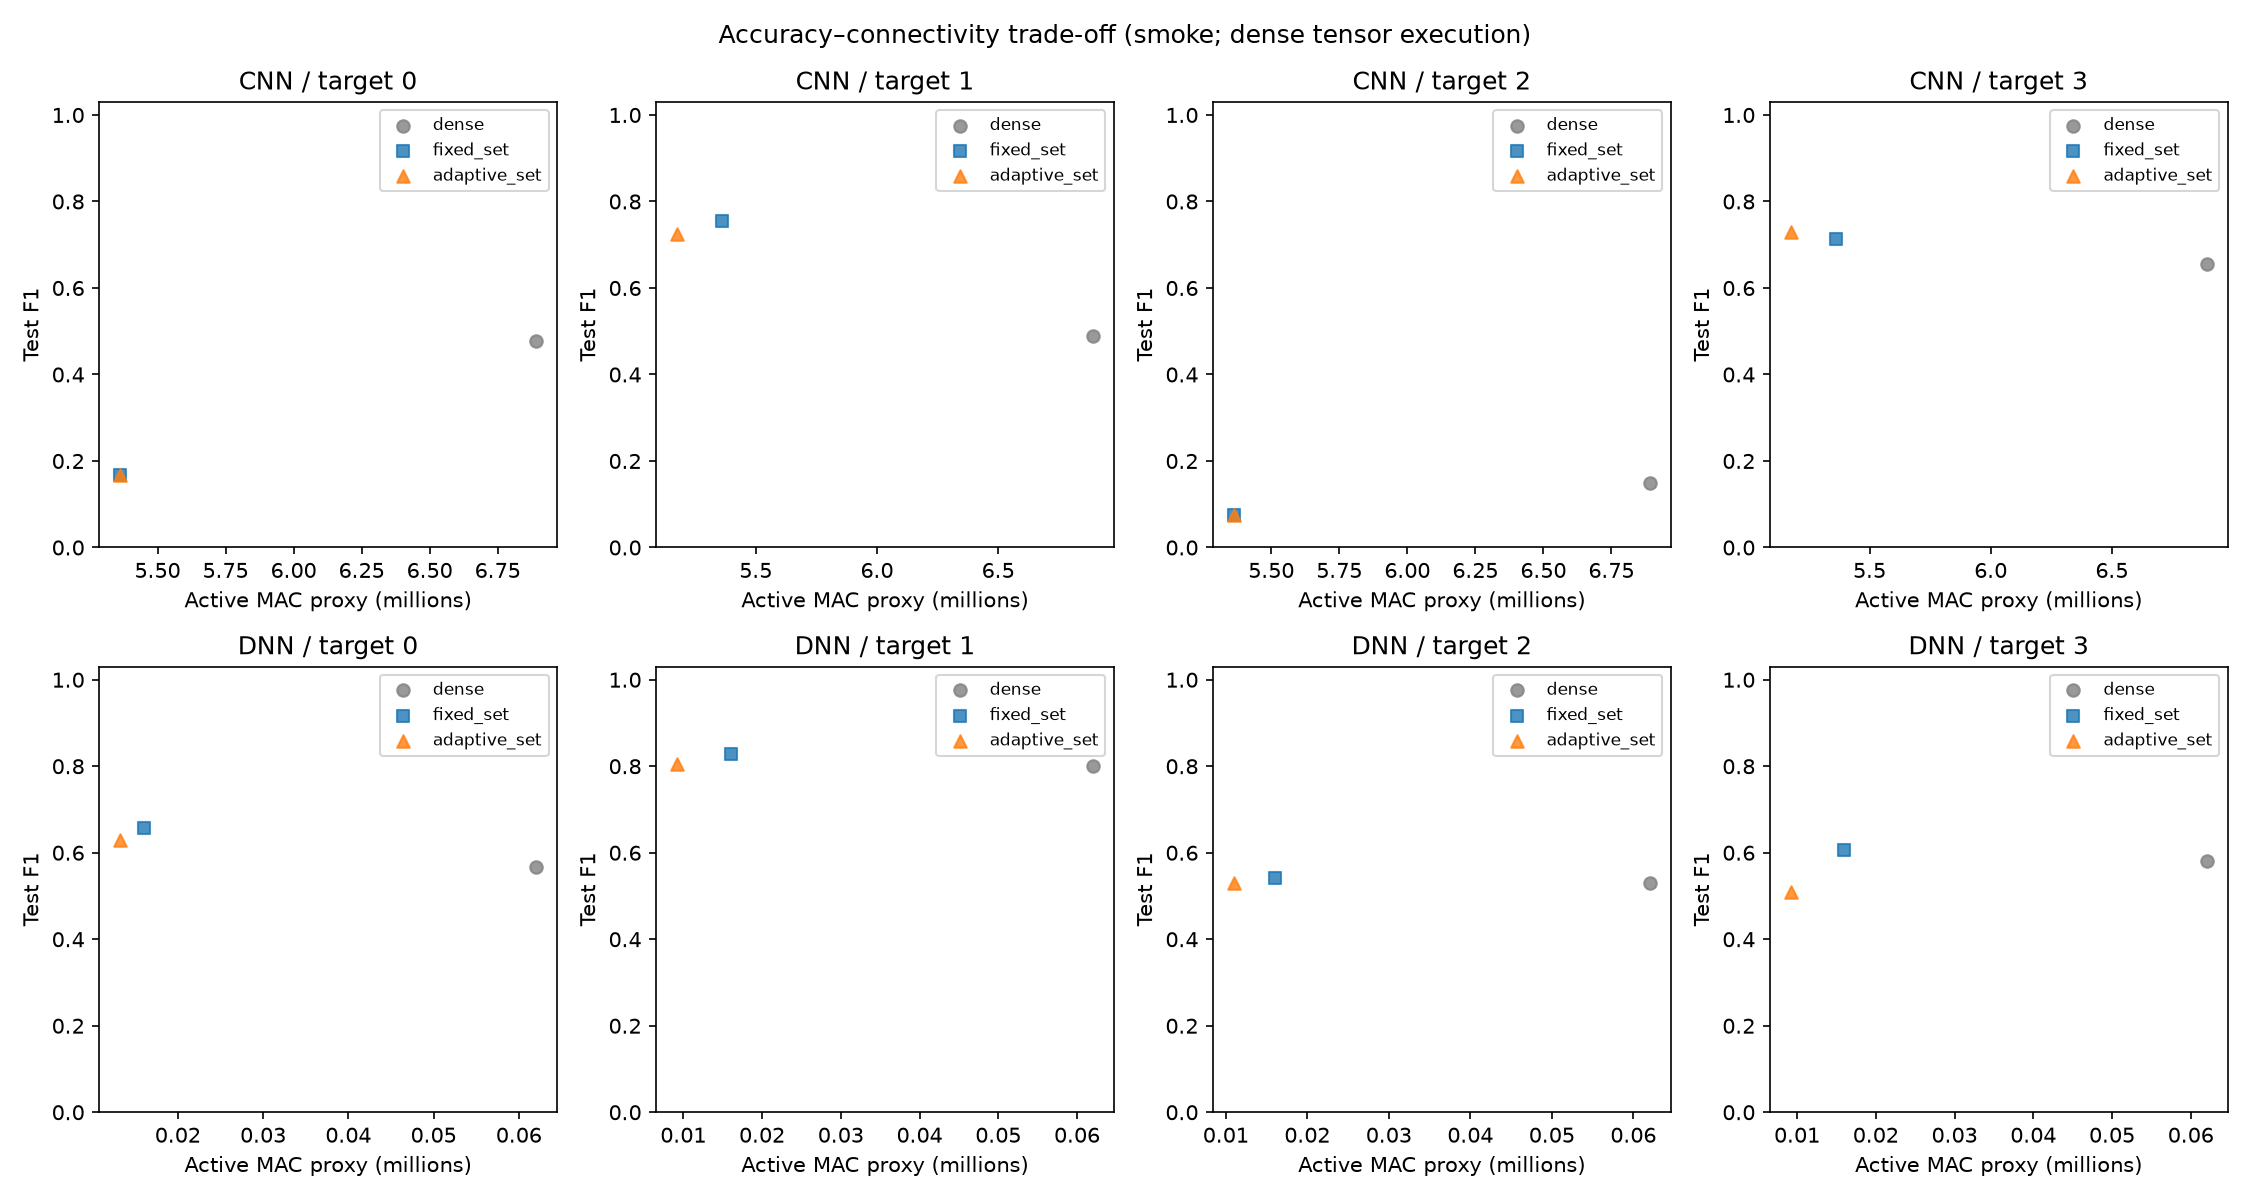

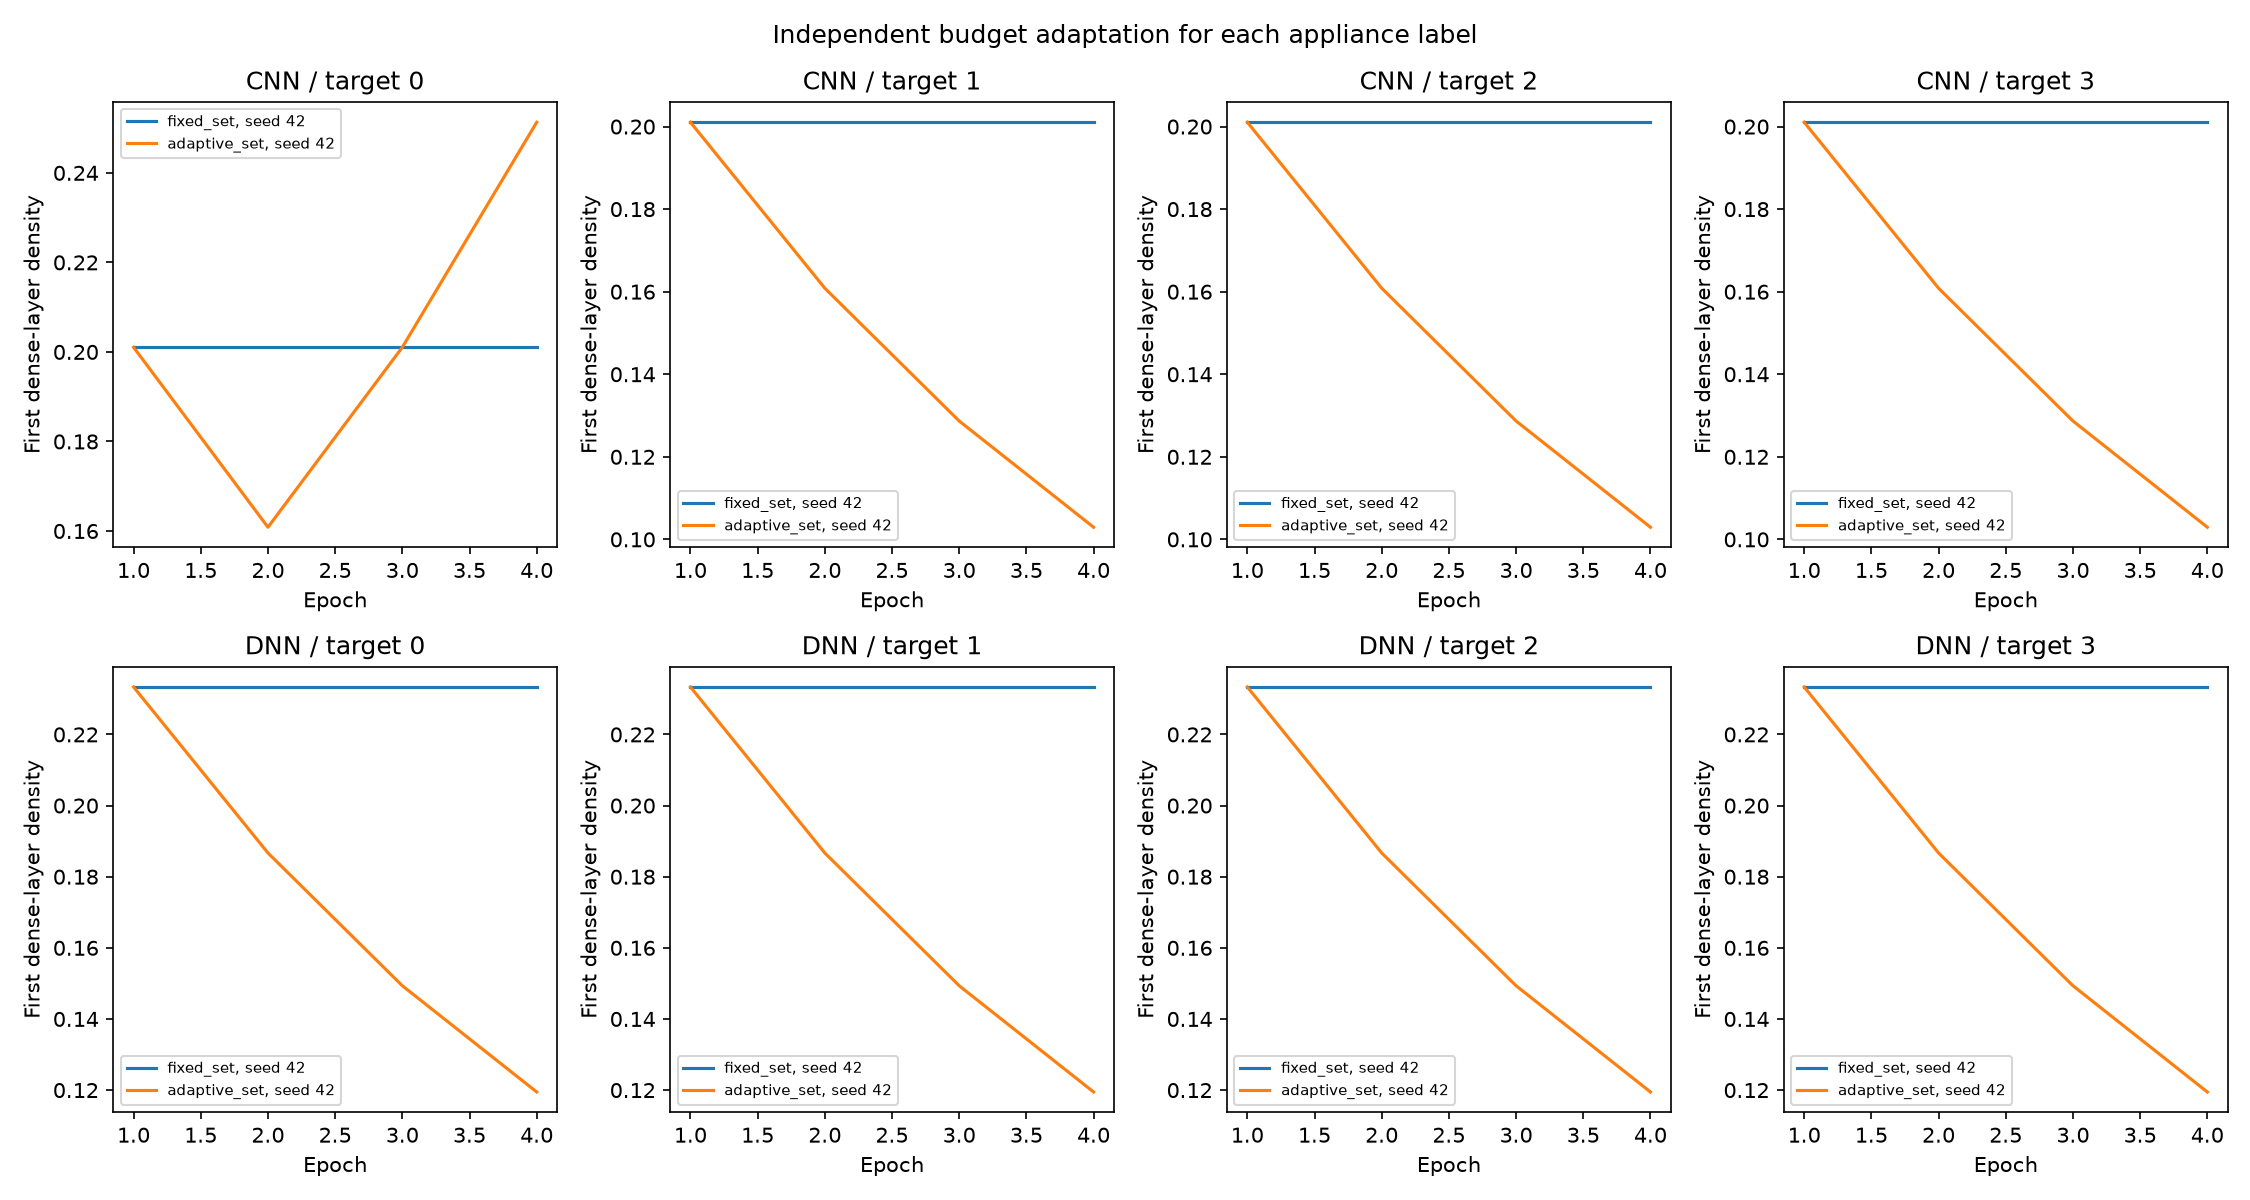

{'architecture': 'CNN', 'target': '0', 'mean_f1_difference': '0.0', 'mean_active_mac_reduction': '0.0', 'descriptive_criterion_met': 'False', 'interpretation': 'execution test only'}
{'architecture': 'CNN', 'target': '1', 'mean_f1_difference': '-0.030579050097592764', 'mean_active_mac_reduction': '0.035012125556764806', 'descriptive_criterion_met': 'False', 'interpretation': 'execution test only'}
{'architecture': 'CNN', 'target': '2', 'mean_f1_difference': '0.0', 'mean_active_mac_reduction': '0.0', 'descriptive_criterion_met': 'False', 'interpretation': 'execution test only'}
{'architecture': 'CNN', 'target': '3', 'mean_f1_difference': '0.015873015873015817', 'mean_active_mac_reduction': '0.035012125556764806', 'descriptive_criterion_met': 'False', 'interpretation': 'execution test only'}
{'architecture': 'DNN', 'target': '0', 'mean_f1_difference': '-0.02868125369603791', 'mean_active_mac_reduction': '0.17478152309612982', 'descriptive_criterion_met': 'False', 'interpretation': 'execu

In [4]:
from IPython.display import display, Image
for filename in ["tradeoff.png", "budget_trajectories.png"]:
    display(Image(filename=str(RESULT_DIR / filename)))
with (RESULT_DIR / "hypothesis_summary.csv").open() as handle:
    comparisons = list(csv.DictReader(handle))
for comparison in comparisons:
    print(comparison)
if MODE == "smoke":
    print("EXECUTION TEST ONLY — the research hypothesis has not been established.")
